In [ ]:

from google.colab import files
import pandas as pd

# Загружаем CSV с компьютера
uploaded = files.upload()


Saving ad_events (1).csv to ad_events (1).csv
Saving experiment_users.csv to experiment_users.csv


In [ ]:

import io

events_name = next(
    name for name in uploaded
    if name.startswith("ad_events")
)

experiment_name = next(
    name for name in uploaded
    if name.startswith("experiment_users")
)

events = pd.read_csv(
    io.BytesIO(uploaded[events_name])
)

experiment = pd.read_csv(
    io.BytesIO(uploaded[experiment_name])
)

print("Рекламные события:", events.shape)
print("Участники A/B-теста:", experiment.shape)

display(experiment.head())


Рекламные события: (209713, 6)
Участники A/B-теста: (20000, 3)


,user_id,experiment_group,exposure_time
0,1,treatment,2026-01-01 00:00:00
1,2,treatment,2026-01-01 00:00:00
2,3,control,2026-01-01 00:00:00
3,4,treatment,2026-01-01 00:00:00
4,5,control,2026-01-01 00:00:00


In [ ]:

print("Столбцы рекламных событий:")
print(events.columns.tolist())

print("\nСтолбцы A/B-теста:")
print(experiment.columns.tolist())

display(experiment.head())


Столбцы рекламных событий:
['event_id', 'user_id', 'campaign_id', 'event_time', 'event_type', 'ad_cost']

Столбцы A/B-теста:
['user_id', 'experiment_group', 'exposure_time']


,user_id,experiment_group,exposure_time
0,1,treatment,2026-01-01 00:00:00
1,2,treatment,2026-01-01 00:00:00
2,3,control,2026-01-01 00:00:00
3,4,treatment,2026-01-01 00:00:00
4,5,control,2026-01-01 00:00:00


In [ ]:
clicked_users = events.loc[
    events["event_type"] == "click",
    "user_id"
].unique()

ab_data = experiment.copy()

ab_data["clicked"] = (
    ab_data["user_id"].isin(clicked_users).astype(int)
)

display(ab_data.head())


,user_id,experiment_group,exposure_time,clicked
0,1,treatment,2026-01-01 00:00:00,0
1,2,treatment,2026-01-01 00:00:00,0
2,3,control,2026-01-01 00:00:00,0
3,4,treatment,2026-01-01 00:00:00,1
4,5,control,2026-01-01 00:00:00,1


In [ ]:

ab_results = (
    ab_data.groupby("experiment_group")
    .agg(
        users=("user_id", "count"),
        clicked_users=("clicked", "sum"),
        conversion=("clicked", "mean")
    )
)

# перевела конверсию в проценты
ab_results["conversion_pct"] = (
    ab_results["conversion"] * 100
)

display(ab_results.round(4))


,users,clicked_users,conversion,conversion_pct
experiment_group,,,,
control,10000,3384,0.3384,33.84
treatment,10000,3722,0.3722,37.22


In [ ]:

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

# Число пользователей с кликом
clicks = [3722, 3384]

# Общее число пользователей
users = [10000, 10000]

# Z-тест для двух долей
z_stat, p_value = proportions_ztest(
    count=clicks,
    nobs=users,
    alternative="two-sided"
)

# 95% доверительный интервал для разницы B - A
ci_low, ci_high = confint_proportions_2indep(
    count1=3722,
    nobs1=10000,
    count2=3384,
    nobs2=10000,
    compare="diff",
    method="newcomb"
)

print(f"Z-статистика: {z_stat:.4f}")
print(f"P-value: {p_value:.8f}")

print(
    f"95% доверительный интервал: "
    f"[{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п."
)

alpha = 0.05

if p_value < alpha:
    print("Различие статистически значимо")
else:
    print("Различие статистически незначимо")


Z-статистика: 4.9937
P-value: 0.00000059
95% доверительный интервал: [2.05; 4.70] п.п.
Различие статистически значимо


In [ ]:

from google.colab import files
import pandas as pd
import io

uploaded_orders = files.upload()

orders_name = next(
    name for name in uploaded_orders
    if name.startswith("orders")
)

orders = pd.read_csv(
    io.BytesIO(uploaded_orders[orders_name])
)

print("Размер таблицы:", orders.shape)
print("Столбцы:", orders.columns.tolist())

display(orders.head())


Saving orders.csv to orders.csv
Размер таблицы: (610, 6)
Столбцы: ['order_id', 'user_id', 'campaign_id', 'order_time', 'revenue', 'status']


,order_id,user_id,campaign_id,order_time,revenue,status
0,1,9144,80,2026-02-18 04:00:42,2667.95,completed
1,2,17968,80,2026-01-10 08:59:40,1681.86,completed
2,3,8350,38,2026-02-11 10:43:21,893.11,completed
3,4,19426,38,2026-01-21 09:19:22,4146.91,completed
4,5,9616,44,2026-01-27 12:05:01,3274.54,completed


In [ ]:

# Отбираем только завершённые заказы
completed_orders = orders[
    orders["status"] == "completed"
].copy()

# Получаем уникальные ID покупателей
buyers = completed_orders["user_id"].unique()

# Добавляем признак покупки в таблицу A/B-теста
ab_data["purchased"] = (
    ab_data["user_id"].isin(buyers).astype(int)
)

# Рассчитываем конверсию в покупку по группам
purchase_results = (
    ab_data.groupby("experiment_group")
    .agg(
        users=("user_id", "count"),
        buyers=("purchased", "sum"),
        purchase_rate=("purchased", "mean")
    )
)

purchase_results["purchase_rate_pct"] = (
    purchase_results["purchase_rate"] * 100
)

display(purchase_results.round(4))

,users,buyers,purchase_rate,purchase_rate_pct
experiment_group,,,,
control,10000,255,0.0255,2.55
treatment,10000,278,0.0278,2.78


In [ ]:

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

control = purchase_results.loc["control"]
treatment = purchase_results.loc["treatment"]

# Покупатели и размеры групп
buyer_counts = [
    int(treatment["buyers"]),
    int(control["buyers"])
]

group_sizes = [
    int(treatment["users"]),
    int(control["users"])
]

# Z-тест
z_stat_purchase, p_value_purchase = proportions_ztest(
    count=buyer_counts,
    nobs=group_sizes,
    alternative="two-sided"
)

# Доверительный интервал разницы B - A
ci_low_purchase, ci_high_purchase = (
    confint_proportions_2indep(
        count1=buyer_counts[0],
        nobs1=group_sizes[0],
        count2=buyer_counts[1],
        nobs2=group_sizes[1],
        compare="diff",
        method="newcomb"
    )
)

# Разница в процентных пунктах
purchase_lift_pp = (
    treatment["purchase_rate"] -
    control["purchase_rate"]
) * 100

print(f"Control: {control['purchase_rate']:.2%}")
print(f"Treatment: {treatment['purchase_rate']:.2%}")

print(f"Разница: {purchase_lift_pp:.3f} п.п.")
print(f"Z-статистика: {z_stat_purchase:.4f}")
print(f"P-value: {p_value_purchase:.6f}")

print(
    f"95% доверительный интервал: "
    f"[{ci_low_purchase * 100:.3f}; "
    f"{ci_high_purchase * 100:.3f}] п.п."
)

if p_value_purchase < 0.05:
    print("Различие статистически значимо")
else:
    print("Статистически значимое различие не обнаружено")


Control: 2.55%
Treatment: 2.78%
Разница: 0.230 п.п.
Z-статистика: 1.0098
P-value: 0.312597
95% доверительный интервал: [-0.217; 0.678] п.п.
Статистически значимое различие не обнаружено


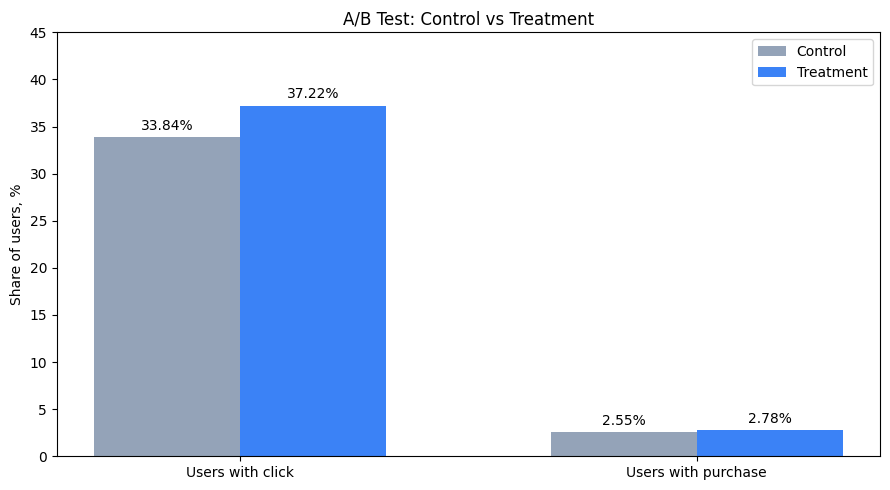

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Users with click", "Users with purchase"]

control_values = [33.84, 2.55]
treatment_values = [37.22, 2.78]

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5))

bars_a = ax.bar(
    x - width / 2,
    control_values,
    width,
    label="Control",
    color="#94A3B8"
)

bars_b = ax.bar(
    x + width / 2,
    treatment_values,
    width,
    label="Treatment",
    color="#3B82F6"
)

ax.bar_label(bars_a, fmt="%.2f%%", padding=3)
ax.bar_label(bars_b, fmt="%.2f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Share of users, %")
ax.set_title("A/B Test: Control vs Treatment")
ax.legend()

ax.set_ylim(0, 45)

plt.tight_layout()
plt.savefig("ab_test_results.png", dpi=300)
plt.show()
